In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.2_xep_hang_dac_trung_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"   # log các notebook EDA để riêng
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 18:05:52 | INFO | Bắt đầu chạy 01_E0.2_xep_hang_dac_trung_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification/logs/2026-11-14_1805_01_E0.2_xep_hang_dac_trung_Han.log


# E0.2 – Yếu tố nào quan trọng nhất? (C2 – Music Genre)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 |
| **Thí nghiệm** | E0.2 – Yếu tố nào quan trọng nhất? |
| **Câu hỏi nghiên cứu** | RQ0: Đặc trưng âm thanh nào phân biệt các thể loại tốt nhất? |
| **Đọc vào** | `data/raw/train.csv` |
| **Ghi ra** | `figures/eda/c2_E0.2_xep_hang_dac_trung.csv` (dùng ở E0.4), 2 hình, `c2_E0.2_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.6 chung một notebook) |
| 14/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

Notebook chỉ dùng thống kê và mô hình đơn giản (hồi quy logistic). Mô hình mạnh là việc của Nhung.

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.6 (Run All). File log nằm ở `logs/eda_log/`. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_C2_Han.ipynb`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Các run W&B của E0.1–E0.6 đã log ngày 08/11 (từ 01_eda_Han.ipynb).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.2": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-2-music-genre-classification"
log.info(f"ROOT: {ROOT}")

2026-11-14 18:05:54 | INFO | ROOT: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET, ID = "Class", "Id"
TEXT_COLS = ["Artist Name", "Track Name"]
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1, E0.2): tách đặc trưng; đổi thời lượng về phút và điền thiếu bằng trung vị
# (chỉ để phân tích, không phải pipeline mô hình); 5 fold phân tầng và hồi quy logistic dùng chung
X = train.drop(columns=[ID, TARGET])
y = train[TARGET]
num_cols = [c for c in X.columns if c not in TEXT_COLS]
Xa = X[num_cols].copy()
Xa["duration_in min/ms"] = np.where(Xa["duration_in min/ms"] < 30, Xa["duration_in min/ms"],
                                    Xa["duration_in min/ms"] / 60000)
Xa = Xa.rename(columns={"duration_in min/ms": "duration_min"})
num_cols = list(Xa.columns)
Xa = Xa.fillna(Xa.median())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
baseline_f1 = 1 / y.nunique()
log.info(f"{len(num_cols)} đặc trưng số, {y.nunique()} thể loại, macro-F1 ngẫu nhiên ≈ {baseline_f1:.3f}")

2026-11-14 18:05:54 | INFO | 14 đặc trưng số, 11 thể loại, macro-F1 ngẫu nhiên ≈ 0.091


## E0.2 – Yếu tố nào quan trọng nhất?

Bốn thước đo cho mỗi đặc trưng số (cột văn bản Artist/Track để riêng cho Nhung xử lý ở E2.2):

1. **Mutual information** với thể loại.
2. **ANOVA F**: trung bình đặc trưng có khác nhau giữa các thể loại không.
3. **Kruskal–Wallis H**: như ANOVA nhưng không giả định phân phối chuẩn.
4. **Macro-F1 đơn biến**: macro-F1 stratified 5-fold của hồi quy logistic chỉ dùng một đặc trưng.

Xếp hạng cuối là thứ hạng trung bình của bốn thước đo.

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))

disc = np.array([c in ["key", "mode", "time_signature"] for c in num_cols])
mi = pd.Series(mutual_info_classif(Xa, y, discrete_features=disc, random_state=SEED), index=num_cols)
f_stat = pd.Series(f_classif(Xa, y)[0], index=num_cols)
kw = pd.Series({c: stats.kruskal(*[Xa.loc[y == k, c] for k in sorted(y.unique())])[0] for c in num_cols})
f1_single = pd.Series({c: cross_val_score(logit(), Xa[[c]], y, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
                       for c in num_cols})

scores = pd.DataFrame({"mutual_info": mi, "ANOVA_F": f_stat, "kruskal_H": kw, "macroF1_don_bien": f1_single})
scores["hang_trung_binh"] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values(["hang_trung_binh", "macroF1_don_bien"], ascending=[True, False])
scores.to_csv(FIG / "c2_E0.2_xep_hang_dac_trung.csv")
baseline_f1 = 1 / y.nunique()
print(f"Macro-F1 nếu đoán ngẫu nhiên đều các lớp ≈ {baseline_f1:.3f}")
scores.round(3)

Macro-F1 nếu đoán ngẫu nhiên đều các lớp ≈ 0.091


,mutual_info,ANOVA_F,kruskal_H,macroF1_don_bien,hang_trung_binh
acousticness,0.282,759.494,5259.593,0.143,1.25
energy,0.218,658.929,4049.752,0.153,2.00
danceability,0.153,457.338,3343.680,0.120,4.00
speechiness,0.152,690.551,2739.611,0.119,4.00
loudness,0.131,615.613,2487.975,0.132,4.50
instrumentalness,0.164,456.800,1870.686,0.060,6.25
Popularity,0.092,162.099,1361.928,0.075,7.25
valence,0.091,226.241,1949.440,0.072,7.25
duration_min,0.057,93.871,1080.501,0.073,8.75
tempo,0.074,31.780,306.108,0.048,10.75


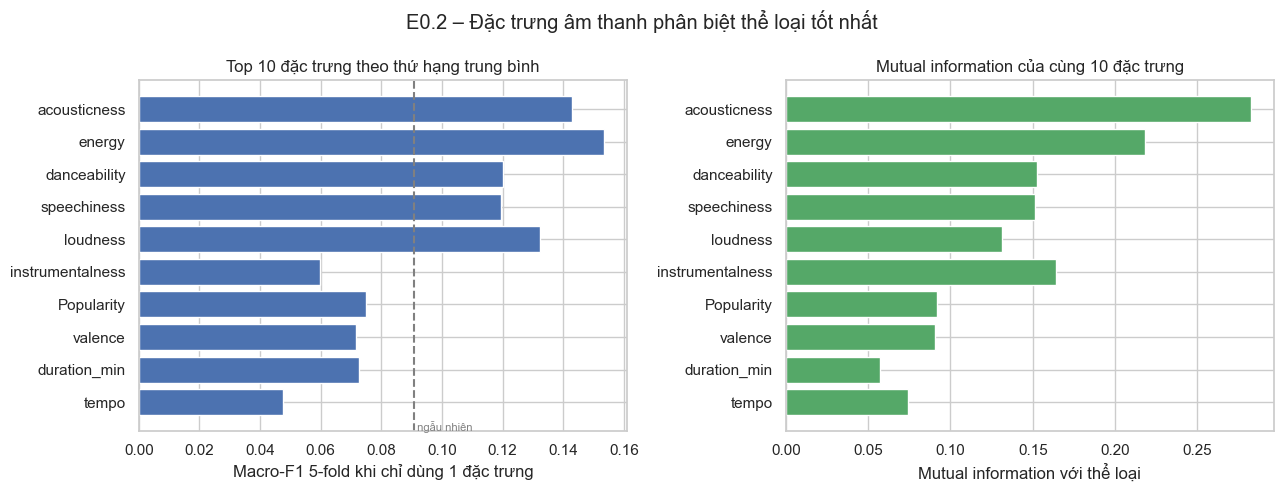

In [6]:
top10 = scores.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top10.index[::-1], top10["macroF1_don_bien"][::-1], color="#4C72B0")
axes[0].axvline(baseline_f1, ls="--", color="gray"); axes[0].text(baseline_f1, -0.9, " ngẫu nhiên", fontsize=8, color="gray")
axes[0].set_xlabel("Macro-F1 5-fold khi chỉ dùng 1 đặc trưng")
axes[0].set_title("Top 10 đặc trưng theo thứ hạng trung bình")
axes[1].barh(top10.index[::-1], top10["mutual_info"][::-1], color="#55A868")
axes[1].set_xlabel("Mutual information với thể loại")
axes[1].set_title("Mutual information của cùng 10 đặc trưng")
fig.suptitle("E0.2 – Đặc trưng âm thanh phân biệt thể loại tốt nhất")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.2_top10_dac_trung.png", dpi=150); plt.show()

2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:05:59 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


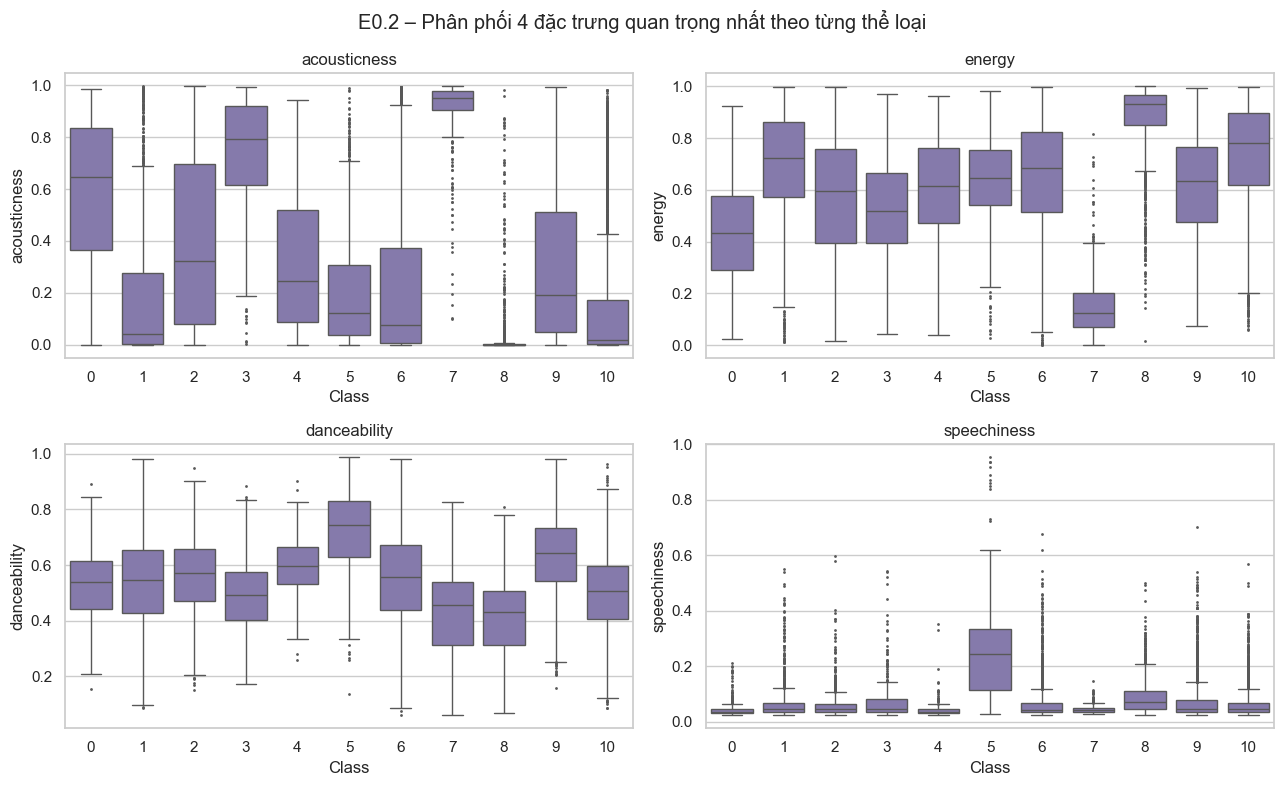

In [7]:
top4 = list(scores.index[:4])
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), top4):
    sns.boxplot(x=y, y=Xa[c], ax=ax, color="#8172B3", fliersize=1)
    ax.set_xlabel("Class"); ax.set_title(c)
fig.suptitle("E0.2 – Phân phối 4 đặc trưng quan trọng nhất theo từng thể loại")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.2_top4_theo_lop.png", dpi=150); plt.show()

## Tóm tắt E0.2

In [8]:
summary = f"""E0.2 (C2): xếp hạng đặc trưng: {', '.join(scores.index[:10])}.
  Đặc trưng đơn lẻ tốt nhất: {scores['macroF1_don_bien'].idxmax()} (macro-F1 = {scores['macroF1_don_bien'].max():.3f}, ngẫu nhiên ≈ {baseline_f1:.3f})."""
log.info("Tóm tắt E0.2:\n" + summary)
(FIG / "c2_E0.2_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:05:59 | INFO | Tóm tắt E0.2:
E0.2 (C2): xếp hạng đặc trưng: acousticness, energy, danceability, speechiness, loudness, instrumentalness, Popularity, valence, duration_min, tempo.
  Đặc trưng đơn lẻ tốt nhất: energy (macro-F1 = 0.153, ngẫu nhiên ≈ 0.091).


225

## Log lên W&B (minh chứng)

In [9]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.2", "c2-E0.2-Han-xep-hang-dac-trung",
            {"best_single_feature_f1": float(scores["macroF1_don_bien"].max())},
            {"bang_xep_hang": scores.round(4).reset_index(names="dac_trung")},
            ["c2_E0.2_top10_dac_trung.png", "c2_E0.2_top4_theo_lop.png"],
            {"cv": "stratified 5-fold", "measures": ["mutual_info", "anova_f", "kruskal", "macro_f1_don_bien"]})

## Nhật ký

- 08/11/2026 – Viết E0.2 lần đầu trong notebook `01_eda_Han.ipynb`. Commit `3f161ad`.
- 14/11/2026 – Tách E0.2 ra thành notebook riêng `01_E0.2_xep_hang_dac_trung_Han.ipynb`, thêm ô ghi log. Commit `eaa2795`.